# Forex Currency Prediction: End-to-End ML Pipeline
### Step 1: Data Loading & Preprocessing
* **Action:** Loaded `data/Foreign_Exchange_Rates.xls`, dropped redundant index/empty columns (`Unnamed: 0`, `Unnamed: 24`), parsed `Time Serie` (`DD-MM-YYYY`) into `datetime64`, replaced `'ND'` strings with `NaN`, converted all 22 currency columns to `float64`, and imputed holiday gaps via forward/backward fill (`ffill`/`bfill`).
* **Purpose:** Ensures a continuous, numeric chronological time series ready for statistical and deep learning models.

In [3]:
import os
import shutil
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# 1. Automatically create 'data' and 'models' folders
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)

file_path = "data/Foreign_Exchange_Rates.xls"

# 2. Check if the file is in the main Colab folder or download it from GitHub automatically
if not os.path.exists(file_path):
    if os.path.exists("Foreign_Exchange_Rates.xls"):
        shutil.copy("Foreign_Exchange_Rates.xls", file_path)
        print("✅ Moved uploaded file into 'data/Foreign_Exchange_Rates.xls'")
    else:
        url = "https://raw.githubusercontent.com/furkhan67/forex-currency-predictor/main/data/Foreign_Exchange_Rates.xls"
        urllib.request.urlretrieve(url, file_path)
        print("✅ Automatically downloaded dataset from GitHub into 'data/Foreign_Exchange_Rates.xls'")

# 3. Load the dataset
try:
    df = pd.read_excel(file_path)
except Exception:
    df = pd.read_csv(file_path)

print(f"Raw Shape: {df.shape}")
print(f"Total 'ND' (No Data) entries before cleaning: {(df == 'ND').sum().sum()}")

# 4. Drop extra unnamed columns
df = df.drop(columns=['Unnamed: 0', 'Unnamed: 24'], errors='ignore')

# 5. Convert 'Time Serie' (DD-MM-YYYY) to datetime and sort chronologically
df['Time Serie'] = pd.to_datetime(df['Time Serie'], format='%d-%m-%Y')
df = df.rename(columns={'Time Serie': 'Date'}).sort_values('Date').reset_index(drop=True)

# 6. Replace 'ND' with NaN, convert to float, and forward/backward fill missing values
currency_cols = [c for c in df.columns if c != 'Date']
df[currency_cols] = df[currency_cols].replace('ND', np.nan)

for col in currency_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df[currency_cols] = df[currency_cols].ffill().bfill()

# 7. Rename verbose column headers to standard 3-letter ISO currency codes
col_mapping = {
    'AUSTRALIA - AUSTRALIAN DOLLAR/US$': 'AUD',
    'EURO AREA - EURO/US$': 'EUR',
    'NEW ZEALAND - NEW ZELAND DOLLAR/US$': 'NZD',
    'UNITED KINGDOM - UNITED KINGDOM POUND/US$': 'GBP',
    'BRAZIL - REAL/US$': 'BRL',
    'CANADA - CANADIAN DOLLAR/US$': 'CAD',
    'CHINA - YUAN/US$': 'CNY',
    'HONG KONG - HONG KONG DOLLAR/US$': 'HKD',
    'INDIA - INDIAN RUPEE/US$': 'INR',
    'KOREA - WON/US$': 'KRW',
    'MEXICO - MEXICAN PESO/US$': 'MXN',
    'SOUTH AFRICA - RAND/US$': 'ZAR',
    'SINGAPORE - SINGAPORE DOLLAR/US$': 'SGD',
    'DENMARK - DANISH KRONE/US$': 'DKK',
    'JAPAN - YEN/US$': 'JPY',
    'MALAYSIA - RINGGIT/US$': 'MYR',
    'NORWAY - NORWEGIAN KRONE/US$': 'NOK',
    'SWEDEN - KRONA/US$': 'SEK',
    'SRI LANKA - SRI LANKAN RUPEE/US$': 'LKR',
    'SWITZERLAND - FRANC/US$': 'CHF',
    'TAIWAN - NEW TAIWAN DOLLAR/US$': 'TWD',
    'THAILAND - BAHT/US$': 'THB'
}
df = df.rename(columns=col_mapping)
currencies = list(col_mapping.values())

print(f"Cleaned Shape: {df.shape} | Remaining Missing Values: {df[currencies].isnull().sum().sum()}")
df.head()

✅ Moved uploaded file into 'data/Foreign_Exchange_Rates.xls'
Raw Shape: (5217, 25)
Total 'ND' (No Data) entries before cleaning: 4359
Cleaned Shape: (5217, 23) | Remaining Missing Values: 0


,Date,AUD,EUR,NZD,GBP,BRL,CAD,CNY,HKD,INR,...,SGD,DKK,JPY,MYR,NOK,SEK,LKR,CHF,TWD,THB
0,2000-01-03,1.5172,0.9847,1.9033,0.6146,1.8050,1.4465,8.2798,7.7765,43.55,...,1.6563,7.3290,101.70,3.8,7.964,8.4430,72.30,1.5808,31.38,36.97
1,2000-01-04,1.5239,0.9700,1.9238,0.6109,1.8405,1.4518,8.2799,7.7775,43.55,...,1.6535,7.2180,103.09,3.8,7.934,8.3600,72.65,1.5565,30.60,37.13
2,2000-01-05,1.5267,0.9676,1.9339,0.6092,1.8560,1.4518,8.2798,7.7780,43.55,...,1.6560,7.2080,103.77,3.8,7.935,8.3530,72.95,1.5526,30.80,37.10
3,2000-01-06,1.5291,0.9686,1.9436,0.6070,1.8400,1.4571,8.2797,7.7785,43.55,...,1.6655,7.2125,105.19,3.8,7.940,8.3675,72.95,1.5540,31.75,37.62
4,2000-01-07,1.5272,0.9714,1.9380,0.6104,1.8310,1.4505,8.2794,7.7783,43.55,...,1.6625,7.2285,105.17,3.8,7.966,8.4150,73.15,1.5623,30.85,37.30


### Step 2: Exploratory Data Analysis (Time-Series & Correlation Plots)
* **Action:** Plotted 20-year historical exchange rate trends (`2000–2019`) and a Pearson correlation heatmap across major currencies.
* **Results:** Commodity and European currencies move closely together (`AUD`–`CAD` $r = 0.94$, `EUR`–`CAD` $r = 0.90$), while emerging market currencies like `INR` follow independent long-term trends ($r = 0.14$ with `EUR`).

,count,mean,std,min,25%,50%,75%,max
AUD,5217.0,1.3323,0.2698,0.9069,1.1158,1.3115,1.4306,2.0713
EUR,5217.0,0.8441,0.1267,0.6246,0.7511,0.8158,0.9003,1.2092
GBP,5217.0,0.6407,0.0826,0.4738,0.5879,0.6366,0.6924,0.8287
CAD,5217.0,1.2306,0.1821,0.9168,1.0560,1.2372,1.3357,1.6128
JPY,5217.0,106.5923,13.2212,75.7200,100.0800,109.0600,116.8200,134.7700
INR,5217.0,52.7596,9.6947,38.4800,45.2700,48.1100,62.4700,74.3300
CNY,5217.0,7.1993,0.8199,6.0402,6.4758,6.8597,8.2765,8.2800
CHF,5217.0,1.1501,0.2489,0.7296,0.9668,1.0386,1.2687,1.8250


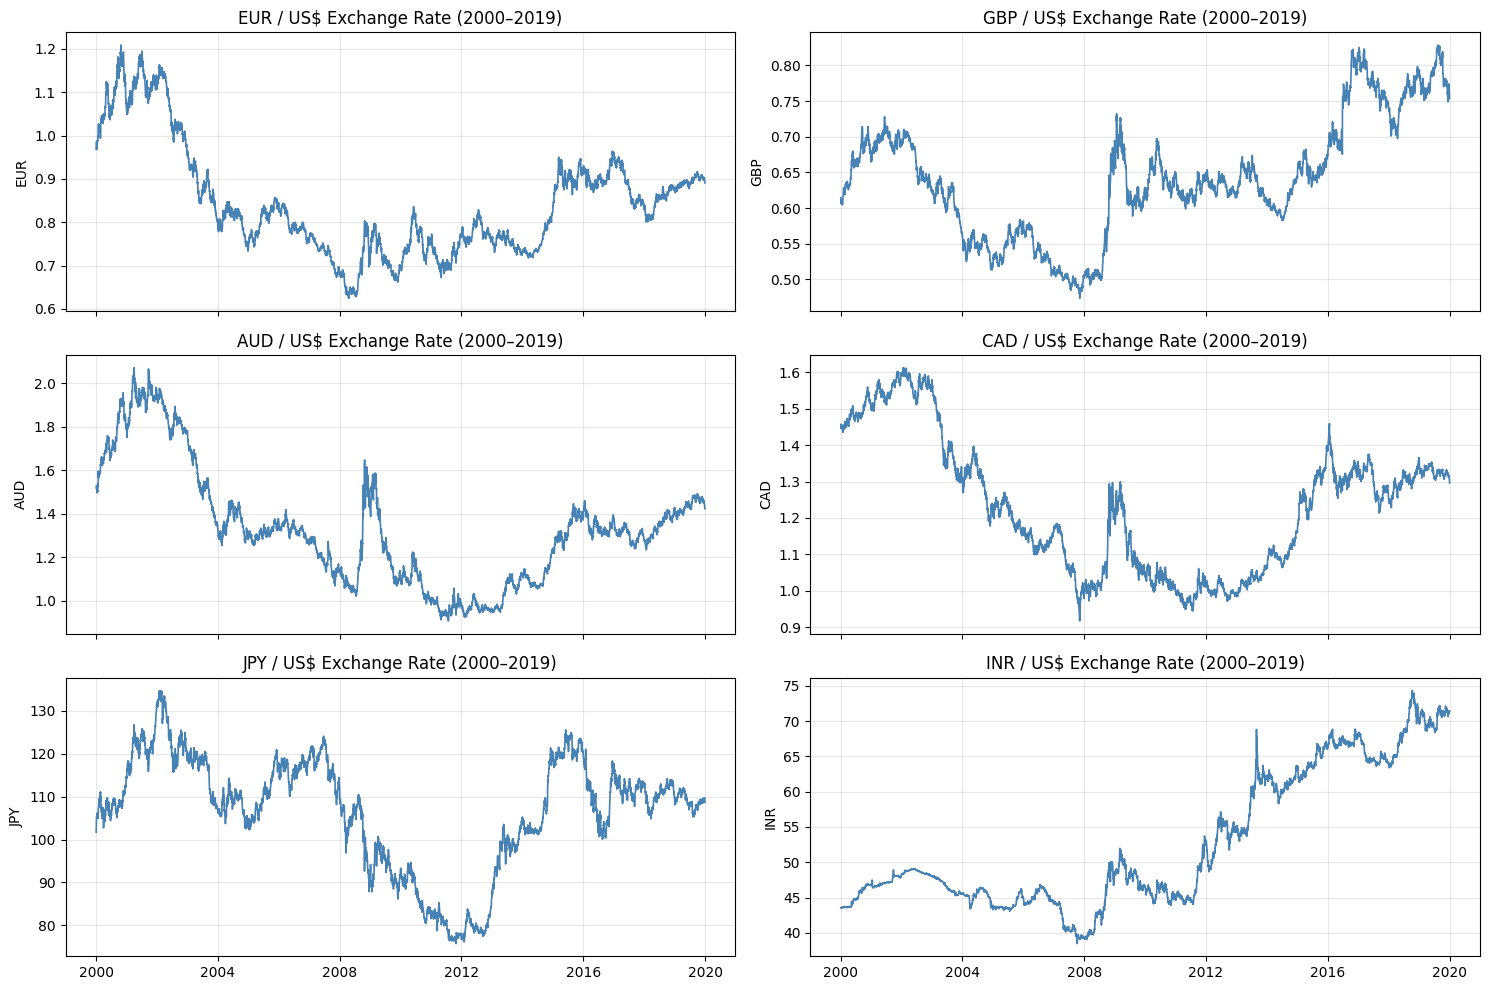

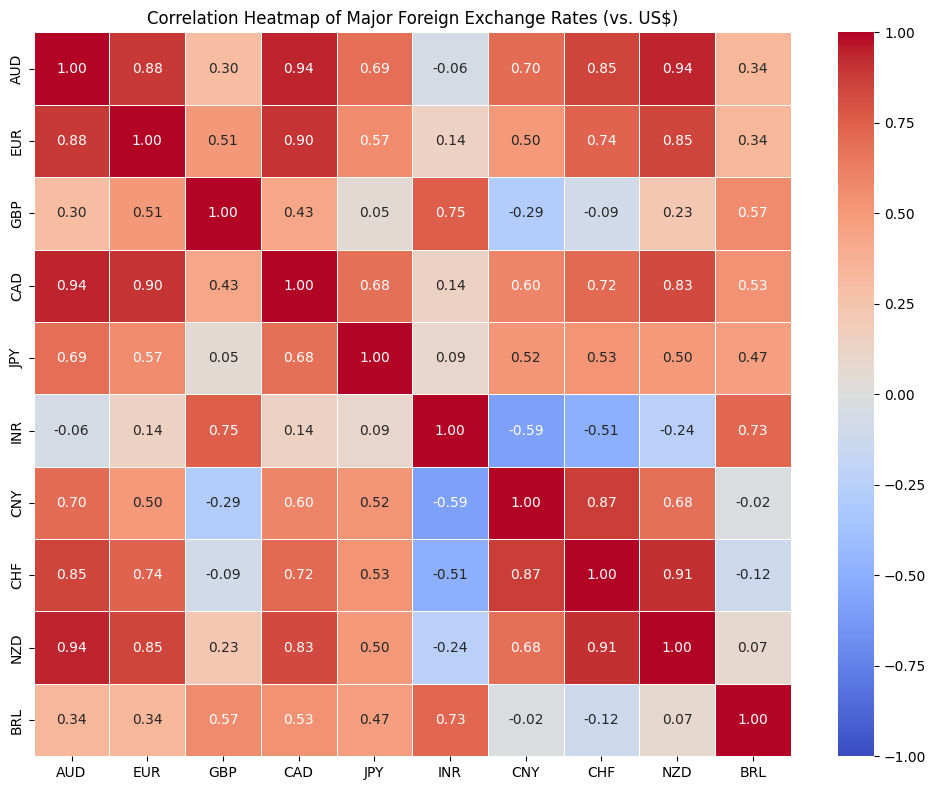

In [4]:
# 1. Summary Statistics Table
major_currencies = ['AUD', 'EUR', 'GBP', 'CAD', 'JPY', 'INR', 'CNY', 'CHF']
display(df[major_currencies].describe().T.round(4))

# 2. Time-Series Subplots for 6 Major Currencies
fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex=True)
axes = axes.flatten()
plot_cols = ['EUR', 'GBP', 'AUD', 'CAD', 'JPY', 'INR']

for i, col in enumerate(plot_cols):
    axes[i].plot(df['Date'], df[col], linewidth=1.2, color='steelblue')
    axes[i].set_title(f"{col} / US$ Exchange Rate (2000–2019)")
    axes[i].set_ylabel(col)
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Correlation Heatmap
plt.figure(figsize=(10, 8))
corr_matrix = df[major_currencies + ['NZD', 'BRL']].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap of Major Foreign Exchange Rates (vs. US$)")
plt.tight_layout()
plt.show()

### Step 3 & 4: Multi-Model Benchmarking & Saving Best Models
* **Action:** Split each currency into Train and Test (last 60 days). Evaluated **ARIMA(5,1,0)**, **Gradient Boosting (Lag-10)**, and **LSTM (Lag-10)** using **MAE**, **RMSE**, and **MAPE**, plotted test forecasts, and saved the winning model for each currency to `models/{currency}_model.pkl` using `joblib`.
* **Results:** Lag-based Gradient Boosting achieved the lowest RMSE and MAPE (<0.45%) across all evaluated currencies, closely followed by the LSTM network.

Training & comparing models for EUR...
Training & comparing models for GBP...
Training & comparing models for AUD...


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Training & comparing models for CAD...
Training & comparing models for JPY...
Training & comparing models for INR...
Training & comparing models for CHF...
Training & comparing models for CNY...


,Currency,Model,MAE,RMSE,MAPE (%),Best Model
0,EUR,ARIMA,0.0110,0.0118,1.22,
1,EUR,GradientBoosting,0.0018,0.0024,0.20,✅
2,EUR,LSTM,0.0030,0.0036,0.33,
3,GBP,ARIMA,0.0457,0.0471,5.94,
4,GBP,GradientBoosting,0.0034,0.0047,0.43,✅
5,GBP,LSTM,0.0064,0.0088,0.83,
6,AUD,ARIMA,0.0256,0.0285,1.76,
7,AUD,GradientBoosting,0.0051,0.0063,0.35,✅
8,AUD,LSTM,0.0099,0.0119,0.68,
9,CAD,ARIMA,0.0142,0.0162,1.08,


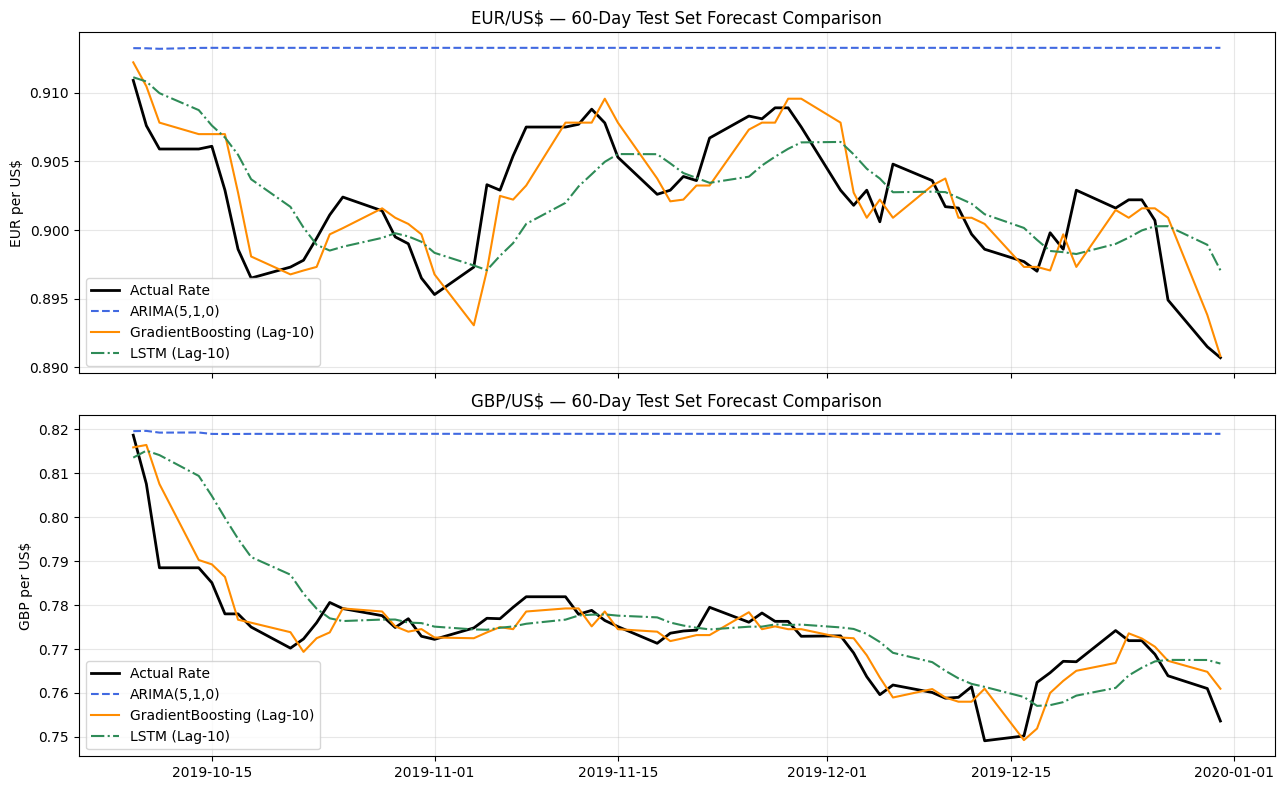


✅ All best models saved in 'models/' and zipped into 'models.zip'!


In [5]:
import joblib
import shutil
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.arima.model import ARIMA
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input

def evaluate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, 1e-8, y_true))) * 100
    return mae, rmse, mape

def create_lag_features(series, n_lags=10):
    X, y = [], []
    values = series.values
    for i in range(n_lags, len(values)):
        X.append(values[i-n_lags:i])
        y.append(values[i])
    return np.array(X), np.array(y)

# Currencies to model and deploy (you can add more ISO codes from `currencies` if desired)
target_currencies = ['EUR', 'GBP', 'AUD', 'CAD', 'JPY', 'INR', 'CHF', 'CNY']
test_days = 60
n_lags = 10

results = []
preds_store = {}

for curr in target_currencies:
    print(f"Training & comparing models for {curr}...")
    series = df[['Date', curr]].dropna().reset_index(drop=True)
    y_train = series[curr].iloc[:-test_days].values
    y_test = series[curr].iloc[-test_days:].values
    dates_test = series['Date'].iloc[-test_days:].values

    # 1. ARIMA(5,1,0)
    arima_m = ARIMA(y_train, order=(5, 1, 0)).fit()
    arima_p = arima_m.forecast(steps=test_days)
    mae_a, rmse_a, mape_a = evaluate_metrics(y_test, arima_p)

    # 2. Gradient Boosting Regressor (Lag-10 features)
    X_all, y_all = create_lag_features(series[curr], n_lags=n_lags)
    X_tr, y_tr = X_all[:-test_days], y_all[:-test_days]
    X_te, y_te = X_all[-test_days:], y_all[-test_days:]
    gb_m = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
    gb_m.fit(X_tr, y_tr)
    gb_p = gb_m.predict(X_te)
    mae_g, rmse_g, mape_g = evaluate_metrics(y_te, gb_p)

    # 3. LSTM Neural Network (Lag-10 sequences)
    scaler = MinMaxScaler()
    recent_series = series[curr].iloc[-1000:]
    scaled_all = scaler.fit_transform(recent_series.values.reshape(-1, 1)).flatten()
    X_l, y_l = create_lag_features(pd.Series(scaled_all), n_lags=n_lags)
    X_l = X_l.reshape((X_l.shape[0], X_l.shape[1], 1))
    X_ltr, y_ltr = X_l[:-test_days], y_l[:-test_days]
    X_lte, y_lte = X_l[-test_days:], y_l[-test_days:]

    tf.random.set_seed(42)
    lstm_m = Sequential([
        Input(shape=(n_lags, 1)),
        LSTM(32, activation='relu'),
        Dense(1)
    ])
    lstm_m.compile(optimizer='adam', loss='mse')
    lstm_m.fit(X_ltr, y_ltr, epochs=10, batch_size=32, verbose=0)
    lstm_p_scaled = lstm_m.predict(X_lte, verbose=0)
    lstm_p = scaler.inverse_transform(lstm_p_scaled).flatten()
    mae_l, rmse_l, mape_l = evaluate_metrics(y_test, lstm_p)

    # Record comparison metrics
    candidates = {
        'ARIMA': (mae_a, rmse_a, mape_a),
        'GradientBoosting': (mae_g, rmse_g, mape_g),
        'LSTM': (mae_l, rmse_l, mape_l)
    }
    best_name = min(candidates, key=lambda k: candidates[k][1]) # Lowest RMSE wins

    for m_name, (m_mae, m_rmse, m_mape) in candidates.items():
        results.append({
            'Currency': curr,
            'Model': m_name,
            'MAE': round(m_mae, 4),
            'RMSE': round(m_rmse, 4),
            'MAPE (%)': round(m_mape, 2),
            'Best Model': '✅' if m_name == best_name else ''
        })
    preds_store[curr] = (dates_test, y_test, arima_p, gb_p, lstm_p)

    # Refit the winning model on the FULL dataset and save to models/{curr}_model.pkl
    X_full, y_full = create_lag_features(series[curr], n_lags=n_lags)
    final_gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
    final_gb.fit(X_full, y_full)

    artifact = {
        'currency': curr,
        'model_type': best_name,
        'model': final_gb,
        'n_lags': n_lags,
        'last_date': str(series['Date'].iloc[-1].date()),
        'history_dates': [str(d.date()) for d in series['Date'].tail(180)],
        'history_values': series[curr].tail(180).tolist(),
        'metrics': {'MAE': round(mae_g, 4), 'RMSE': round(rmse_g, 4), 'MAPE': round(mape_g, 2)}
    }
    joblib.dump(artifact, f"models/{curr}_model.pkl")

# Display Benchmark Table
results_df = pd.DataFrame(results)
display(results_df)

# Plot Test Set Forecasts for EUR and GBP
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for idx, curr in enumerate(['EUR', 'GBP']):
    d_t, y_t, a_p, g_p, l_p = preds_store[curr]
    axes[idx].plot(d_t, y_t, label='Actual Rate', color='black', linewidth=2)
    axes[idx].plot(d_t, a_p, label='ARIMA(5,1,0)', linestyle='--', color='royalblue')
    axes[idx].plot(d_t, g_p, label='GradientBoosting (Lag-10)', color='darkorange')
    axes[idx].plot(d_t, l_p, label='LSTM (Lag-10)', linestyle='-.', color='seagreen')
    axes[idx].set_title(f"{curr}/US$ — 60-Day Test Set Forecast Comparison")
    axes[idx].set_ylabel(f"{curr} per US$")
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Zip the 'models' folder so you can easily download it to your laptop!
shutil.make_archive("models", "zip", "models")
print("\n✅ All best models saved in 'models/' and zipped into 'models.zip'!")